# Two asteroids meet: Vesta and (197) Arete

**The question.** Every ~18 years (its synodic period relative to Vesta) the main-belt asteroid
(197) Arete passes within about 0.04 au (6 million km) of (4) Vesta, the second most massive
body in the asteroid belt. That
repeated pull is how Vesta's mass was first measured (Hertz 1966). When is the next encounter,
how close, how fast, and how well do we know it? And can we see Vesta's pull in Arete's
astrometry ourselves?

PyRoOrb fits both orbits from the MPC's astrometry. We propagate both orbits, plus clouds of
covariance-sampled clones, through the 2030 encounter and check everything against JPL.

Two details matter:
* **Vesta can't be fitted in a field that contains Vesta.** PyRoOrb's optional 16-asteroid
  perturber model (JPL's `sb441-n16` kernel, `pyroorb-fetch-data --asteroids`) includes Vesta,
  so PyRoOrb fits Vesta itself gravity-only (planets + Moon + GR) and says so.
* **Arete *is* fitted with the 16 perturbers**, because, as section 4 shows, it needs them.

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. Fit both orbits

The asteroid-perturber model is a process-wide switch (`force_assist.ASTEROIDS_PATH`; internal
API, may change). For Arete we use its 8,600 observations since 2010: plenty for a 2030
prediction, and the fit takes seconds. (The full 1879-2026 arc also works but takes far
longer.) The `o["jd_utc"]` filter reads an observation record's time (record keys are internal).

In [2]:
import pyroorb.force_assist as fa
from astropy.time import Time

KERNEL = fa.asteroid_kernel_path() or fa.ensure_asteroid_kernel(verbose=True)

def fit(desig, since=None, asteroid_perturbers=True):
    fa.ASTEROIDS_PATH = KERNEL if asteroid_perturbers else None
    obs = pyroorb.fetch_observations(desig)
    if since:
        obs = pyroorb.Observations([o for o in obs if o["jd_utc"] >= Time(since).jd], obs.meta)
    f = pyroorb.fit_orbit(obs, designation=desig)
    print(f"({desig}): {f.n_observations()} of {len(obs)} obs used, rms {f.rms_residual():.2f}\", "
          f"arc {f.arc_length_days() / 365.25:.0f} yr, force model {f.force_model}")
    return f

vesta = fit("4")
arete = fit("197", since="2010-01-01")

(4): 7863 of 8278 obs used, rms 1.23", arc 206 yr, force model ASSIST(DE440+GR, +16ast off: self-perturber)


(197): 8593 of 8651 obs used, rms 0.47", arc 17 yr, force model ASSIST(DE440+GR+16ast)


## 2. The 18-year rhythm

Propagate both nominal orbits from 1990 to 2060 and measure their separation. Each orbit is
propagated in the force model it was fitted in.

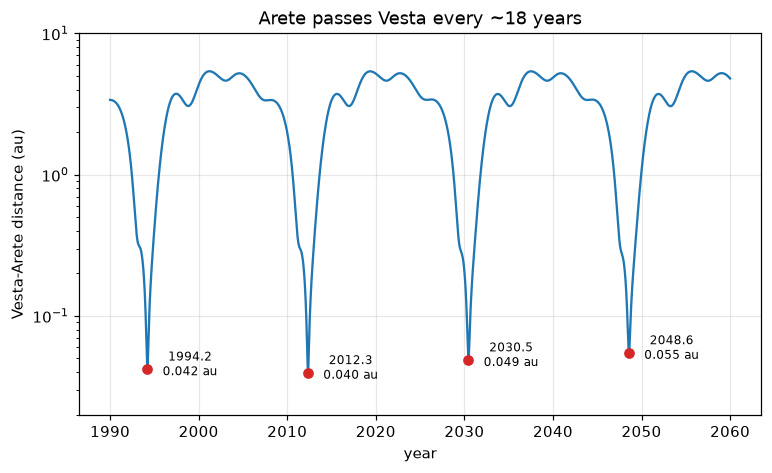

In [3]:
def propagate(f, times_tdb, asteroids, states=None):
    """Heliocentric equatorial states (n_times, n_particles, 6) in au, au/d."""
    states = [np.concatenate(f.state_vector())] if states is None else list(states)
    return fa.helio_states_multi(f.epoch_tdb, states, times_tdb, asteroids=asteroids)

AU_KM = 1.495978707e8
t = Time("1990-01-01").tdb.jd + np.arange(0, 70 * 365.25, 2.0)
sep = np.linalg.norm(propagate(arete, t, True)[:, 0, :3] - propagate(vesta, t, False)[:, 0, :3], axis=1)

yr = 2000 + (t - 2451544.5) / 365.25
mins = [i for i in range(1, len(t) - 1) if sep[i] < sep[i - 1] and sep[i] < sep[i + 1] and sep[i] < 0.1]
plt.semilogy(yr, sep)
plt.plot(yr[mins], sep[mins], "o", color="C3")
for i in mins:
    plt.annotate(f"{yr[i]:.1f}\n{sep[i]:.3f} au", (yr[i], sep[i]), textcoords="offset points",
                 xytext=(28, -4), ha="center", fontsize=8)
plt.xlabel("year"); plt.ylabel("Vesta-Arete distance (au)"); plt.ylim(0.02, 10)
plt.title("Arete passes Vesta every ~18 years")
plt.show()

## 3. The 2030 encounter, with uncertainty

Each fit carries a state covariance. We draw 200 clones of each orbit from it, propagate them
all in one integration per body, and find each clone pair's minimum distance on a one-minute
grid around the encounter.

In [4]:
rng = np.random.default_rng(2030)
def clones(f, n=200):
    s0 = np.concatenate(f.state_vector())
    return np.vstack([s0, rng.multivariate_normal(s0, f.covariance_matrix("state")[:6, :6], n)])

# coarse search for the nominal minimum, then a 1-minute grid +-0.25 d around it
tc = Time("2030-05-01").tdb.jd + np.arange(0, 100, 0.05)
d = np.linalg.norm(propagate(arete, tc, True)[:, 0, :3] - propagate(vesta, tc, False)[:, 0, :3], axis=1)
tf = tc[np.argmin(d)] + np.arange(-0.25, 0.25, 1 / 1440)

A = propagate(arete, tf, True, clones(arete))      # (n_t, 201, 6)
V = propagate(vesta, tf, False, clones(vesta))
dist = np.linalg.norm(A[:, :, :3] - V[:, :, :3], axis=2)          # (n_t, 201)
k = dist.argmin(axis=0)
ca_t, ca_d = tf[k], dist[k, np.arange(dist.shape[1])] * AU_KM
v_rel = np.linalg.norm(A[k[0], 0, 3:] - V[k[0], 0, 3:]) * AU_KM / 86400

ca_utc = Time(ca_t[0], format="jd", scale="tdb").utc
print(f"closest approach : {ca_utc.iso[:16]} UTC  +/- {ca_t.std() * 1440:.0f} min")
print(f"miss distance    : {ca_d[0]:,.0f} km  +/- {ca_d.std():,.0f} km  ({ca_d[0] / AU_KM:.5f} au)")
print(f"relative speed   : {v_rel:.3f} km/s")

closest approach : 2030-06-18 22:16 UTC  +/- 1 min
miss distance    : 7,295,110 km  +/- 47 km  (0.04876 au)
relative speed   : 2.100 km/s


### Check against JPL

JPL's ephemerides for both bodies come from Horizons on the same one-minute grid, in the same
frame (heliocentric, ICRF).

                                 PyRoOrb                   JPL
closest approach        2030-06-18 22:16      2030-06-18 22:15
miss distance km               7,295,110             7,295,255
rel. speed km/s                    2.100                 2.100

position vs JPL at encounter: Arete 28 km, Vesta 183 km


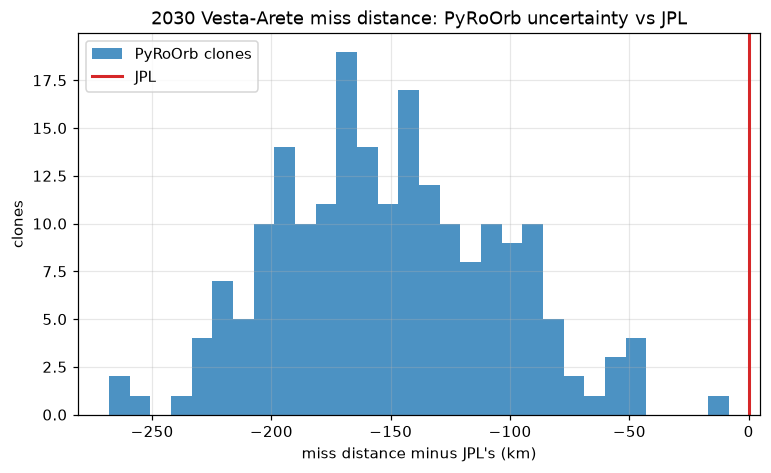

In [5]:
import json, urllib.request, urllib.parse

def horizons_vectors(cmd, jd0, jd1, step="1 m"):
    q = {"format": "json", "COMMAND": f"'{cmd};'", "EPHEM_TYPE": "VECTORS", "CENTER": "'500@10'",
         "START_TIME": f"'JD{jd0}'", "STOP_TIME": f"'JD{jd1}'", "STEP_SIZE": f"'{step}'",
         "VEC_TABLE": "2", "REF_PLANE": "FRAME", "OUT_UNITS": "AU-D", "CSV_FORMAT": "YES"}
    res = json.load(urllib.request.urlopen(
        "https://ssd.jpl.nasa.gov/api/horizons.api?" + urllib.parse.urlencode(q), timeout=60))["result"]
    rows = res.split("$$SOE")[1].split("$$EOE")[0].strip().splitlines()
    return np.array([[float(v) for v in r.split(",")[2:8]] for r in rows])   # TDB grid = tf

ja = horizons_vectors("197", tf[0], tf[-1])[:len(tf)]
jv = horizons_vectors("4", tf[0], tf[-1])[:len(tf)]
jd = np.linalg.norm(ja[:, :3] - jv[:, :3], axis=1) * AU_KM
j = jd.argmin()
print(f"{'':18s}{'PyRoOrb':>22s}{'JPL':>22s}")
print(f"{'closest approach':18s}{ca_utc.iso[:16]:>22s}{Time(tf[j], format='jd', scale='tdb').utc.iso[:16]:>22s}")
print(f"{'miss distance km':18s}{ca_d[0]:>22,.0f}{jd[j]:>22,.0f}")
print(f"{'rel. speed km/s':18s}{v_rel:>22.3f}{np.linalg.norm(ja[j, 3:] - jv[j, 3:]) * AU_KM / 86400:>22.3f}")
print(f"\nposition vs JPL at encounter: Arete {np.linalg.norm(A[k[0], 0, :3] - ja[k[0], :3]) * AU_KM:.0f} km, "
      f"Vesta {np.linalg.norm(V[k[0], 0, :3] - jv[k[0], :3]) * AU_KM:.0f} km")

plt.hist(ca_d - jd[j], bins=30, color="C0", alpha=0.8, label="PyRoOrb clones")
plt.axvline(0, color="C3", lw=2, label="JPL")
plt.xlabel("miss distance minus JPL's (km)"); plt.ylabel("clones")
plt.title("2030 Vesta-Arete miss distance: PyRoOrb uncertainty vs JPL"); plt.legend()
plt.show()

PyRoOrb reproduces JPL's encounter to the minute, and the 7.3-million-km miss distance to
~150 km (0.002%). Note what the histogram shows, though: JPL's value lies about 3σ outside our
clone cloud. The clones represent only the *measurement* uncertainty of the two fits. The
dominant error is a *model* error that no covariance contains. Vesta is ~180 km from JPL's
position at the encounter because PyRoOrb has to fit Vesta without the other big asteroids,
while JPL's Vesta is pulled by Ceres and Pallas. Arete, fitted with the perturbers, is within
~30 km of JPL.

## 4. Seeing Vesta's pull in Arete's astrometry

Refit Arete's same observations **without** the asteroid perturbers and look at the
residuals (observed minus computed), binned every six months.

(197): 6520 of 8651 obs used, rms 0.49", arc 17 yr, force model ASSIST(DE440+GR)


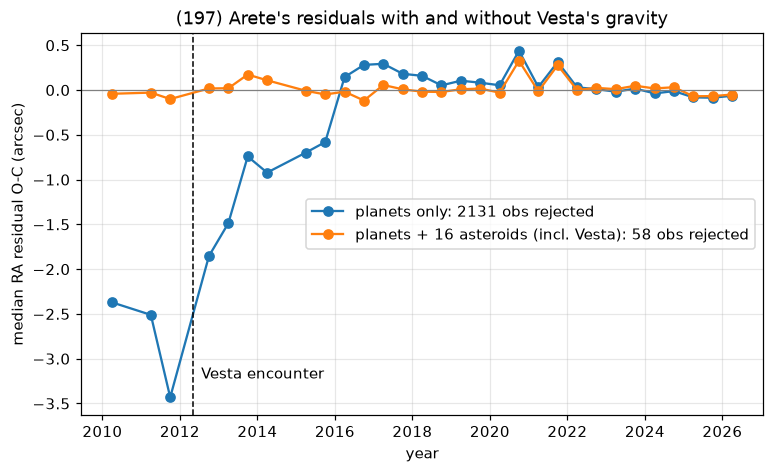

In [6]:
arete_grav = fit("197", since="2010-01-01", asteroid_perturbers=False)

def binned(f, width=0.5):
    r = f.residuals()
    yr_obs = 2000 + (np.array([x["jd_utc"] for x in r]) - 2451544.5) / 365.25
    dra = np.array([x["d_ra_arcsec"] for x in r])
    edges = np.arange(2010, 2026.6, width)
    mid = [(a + b) / 2 for a, b in zip(edges[:-1], edges[1:]) if ((yr_obs >= a) & (yr_obs < b)).sum() > 5]
    med = [np.median(dra[(yr_obs >= m - width / 2) & (yr_obs < m + width / 2)]) for m in mid]
    return mid, med

for f, lab in [(arete_grav, "planets only"), (arete, "planets + 16 asteroids (incl. Vesta)")]:
    plt.plot(*binned(f), "o-", label=f"{lab}: {f.n_excluded()} obs rejected")
enc = yr[mins][np.argmin(abs(yr[mins] - 2012))]
plt.axvline(enc, color="k", ls="--", lw=1)
plt.text(enc + 0.2, plt.ylim()[0] * 0.9, "Vesta encounter", va="bottom")
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("year"); plt.ylabel("median RA residual O-C (arcsec)")
plt.title("(197) Arete's residuals with and without Vesta's gravity"); plt.legend()
plt.show()

Without the asteroids, the orbit that fits the post-2012 data misses the pre-encounter
observations by 2-3 arcseconds, and the fit has to reject a quarter of all observations to
converge. With the 16 perturbers the residuals are flat. A back-of-the-envelope impulse
estimate shows that Vesta's pull is of the right order to explain it:

In [7]:
GM_VESTA = 17.29                   # km^3/s^2 (Dawn)
b_km, v_kms = sep[mins][np.argmin(abs(yr[mins] - 2012))] * AU_KM, v_rel
dv = 2 * GM_VESTA / (b_km * v_kms)             # impulse approximation, km/s
drift = 3 * dv * 8 * 3.156e7                   # along-track drift after ~8 years, km
print(f"Vesta's kick at {b_km / 1e6:.1f} million km: {dv * 1e6:.1f} mm/s")
print(f"along-track drift after 8 yr ~ {drift:,.0f} km ~ {np.degrees(drift / (2 * AU_KM)) * 3600:.1f} arcsec at 2 au")

Vesta's kick at 5.9 million km: 2.8 mm/s
along-track drift after 8 yr ~ 2,103 km ~ 1.4 arcsec at 2 au


A few millimetres per second, accumulated over years of orbital motion, gives arcseconds on
the sky. That is why Arete's orbit carries information about Vesta's mass.

**Caveats.** The 16-perturber switch turns on all of them (Ceres, Pallas, Hygiea, ...), so
section 4 shows the combined effect. The timing (a step at the 2012 encounter) and the size of
the impulse estimate point to Vesta. Most of the remaining difference from JPL comes from Vesta's
own orbit: PyRoOrb must fit Vesta gravity-only, while JPL's Vesta feels Ceres and Pallas.